In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from keras import layers, models
from keras.utils import plot_model
from keras.optimizers import Adam
from keras.metrics import AUC, Precision, Recall
from keras.callbacks import ModelCheckpoint

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_curve, precision_recall_curve,
    confusion_matrix, classification_report
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Load the datasest
# To avoid any issue, the dataset should be in the Google Drive at: COE 547 - Final Project > ECG_10s_2500.csv'
file_path = '/content/drive/MyDrive/COE 547 - Final Project/ECG_10s_2500.csv'
df = pd.read_csv(file_path)

In [ ]:
# Number of patients
patients_number = df['patient_id'].nunique()
print(f'The total number of patients is: {patients_number}')

The total number of patients is: 9


In [ ]:
# Group by patient_id and label to count occurrences
patient_label_counts = df.groupby(['patient_id', 'label']).size().unstack(fill_value=0)
patient_label_counts = patient_label_counts.rename(columns={0: 'non_hypo', 1: 'hypo'})

print("Number of hypo and non-hypo cases per patient:")
print(patient_label_counts)

Number of hypo and non-hypo cases per patient:
label       non_hypo  hypo
patient_id                
1                515    54
2               4026   372
3               1723     0
4               1968   358
5                 44     0
6               5621     0
7              14360     3
8              14886  1674
9                 26     0


In [ ]:
# Dataset balance
df["label"].value_counts()

,count
label,
0,43169
1,2461


In [ ]:
# Drop the additional metadata
cols_to_drop = ["day", "count", "glucose_values", "patient_id"]
existing = [c for c in cols_to_drop if c in df.columns]
df = df.drop(columns=existing)

In [ ]:
# Separate the features from the labels
ecg_cols = [c for c in df.columns if c != "label"]
X = df[ecg_cols].to_numpy(dtype=np.float32)
y = df["label"].to_numpy(dtype=np.int32)

In [ ]:
# Split the data into train (70%), validation (15%), and testing (15%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

In [ ]:
input_length = X_train.shape[1]

X_train = X_train.reshape(-1, input_length, 1)
X_val   = X_val.reshape(-1, input_length, 1)
X_test  = X_test.reshape(-1, input_length, 1)

In [ ]:
# Augment the dataset by overlapping original samples
def slice_with_overlap(X, y, window_size=500, overlap=0.5):
    step = int(window_size * (1 - overlap))

    X_new = []
    y_new = []

    for i in range(len(X)):
        signal = X[i].squeeze()
        T = len(signal)

        # slide window
        for start in range(0, T - window_size + 1, step):
            end = start + window_size
            seg = signal[start:end]
            X_new.append(seg.reshape(window_size, 1))
            y_new.append(y[i])

    return np.array(X_new), np.array(y_new)

In [ ]:
# Only a 50% overlap on the training dataset
# All samples are converted from 10s to 2s
window_size = 500   # 2500 / 500 = 2s

X_train_win, y_train_win = slice_with_overlap(
    X_train, y_train,
    window_size=window_size,
    overlap=0.5
)

X_val_win, y_val_win = slice_with_overlap(
    X_val, y_val,
    window_size=window_size,
    overlap=0.0
)

X_test_win, y_test_win = slice_with_overlap(
    X_test, y_test,
    window_size=window_size,
    overlap=0.0
)

In [ ]:
X_pos = X_train[y_train == 1]
X_neg = X_train[y_train == 0]

print("Before balancing:", len(X_pos), "hypo |", len(X_neg), "normal")

Before balancing: 1723 hypo | 30218 normal


In [ ]:
def show_balance(name, y):
    total = len(y)
    pos = np.sum(y == 1)
    neg = np.sum(y == 0)
    print(f"===== {name} =====")
    print(f"Total samples: {total}")
    print(f"Non-Hypo (0): {neg}")
    print(f"Hypo     (1): {pos}")
    print()

show_balance("TRAIN (after slicing)", y_train_win)
show_balance("VAL   (after slicing)", y_val_win)
show_balance("TEST  (after slicing)", y_test_win)

===== TRAIN (after slicing) =====
Total samples: 287469
Non-Hypo (0): 271962
Hypo     (1): 15507

===== VAL   (after slicing) =====
Total samples: 34220
Non-Hypo (0): 32375
Hypo     (1): 1845

===== TEST  (after slicing) =====
Total samples: 34225
Non-Hypo (0): 32380
Hypo     (1): 1845



In [ ]:
# Build the model
def build_model(input_length):
    inp = layers.Input(shape=(input_length,1))

    x = layers.Conv1D(32, 15, padding='same', activation='relu')(inp)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(64, 11, padding='same', activation='relu')(x)
    x = layers.MaxPooling1D(2)(x)

    x = layers.Conv1D(128, 7, padding='same', activation='relu')(x)

    x = layers.Bidirectional(layers.LSTM(64))(x)
    x = layers.Dense(64, activation='relu')(x)
    x = layers.Dropout(0.3)(x)

    out = layers.Dense(1, activation='sigmoid')(x)

    return models.Model(inputs=inp, outputs=out)

model = build_model(window_size)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 500, 1)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 500, 32)        │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 250, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 250, 64)        │        22,592 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_3 (MaxPooling1D)  │ (None, 125, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 125, 128)       │        57,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 128)            │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 187,713 (733.25 KB)

 Trainable params: 187,713 (733.25 KB)

 Non-trainable params: 0 (0.00 B)

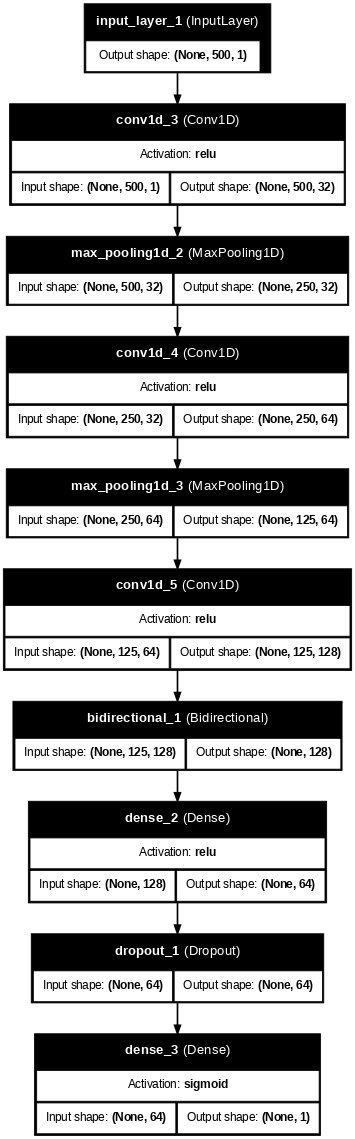

In [ ]:
# Plot the architecture
plot_model(
    model,
    to_file="model_architecture.png",
    show_shapes=True,
    show_layer_names=True,
    rankdir="TB",
    expand_nested=False,
    dpi=60,
    show_dtype=False,
    show_layer_activations=True
)


In [ ]:
# Compile the model
model.compile(
    optimizer=Adam(1e-3),
    loss='binary_crossentropy',
    metrics=[
        AUC(name='roc_auc'),
        AUC(name='pr_auc', curve='PR'),
        Precision(name='precision'),
        Recall(name='recall')
    ]
)

In [ ]:
# Define ModelCheckpoint callback to save the weights in our Google Drive
checkpoint = ModelCheckpoint(
    filepath='best_model.h5',
    monitor='val_pr_auc',
    save_best_only=True,
    save_weights_only=False,
    mode='max'
)

In [ ]:
history = model.fit(
    X_train_win, y_train_win,
    validation_data=(X_val_win, y_val_win),
    epochs=40,
    batch_size=128,
    class_weight={0: 1, 1: 4},
    callbacks=[checkpoint]
)

Epoch 1/40
2246/2246 ━━━━━━━━━━━━━━━━━━━━ 59s 24ms/step - loss: 0.5648 - pr_auc: 0.0586 - precision: 0.0692 - recall: 7.6476e-04 - roc_auc: 0.5277 - val_loss: 0.2852 - val_pr_auc: 0.0585 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_roc_auc: 0.5185
Epoch 2/40
2246/2246 ━━━━━━━━━━━━━━━━━━━━ 52s 23ms/step - loss: 0.5403 - pr_auc: 0.0652 - precision: 0.0000e+00 - recall: 0.0000e+00 - roc_auc: 0.5721 - val_loss: 0.2524 - val_pr_auc: 0.1283 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_roc_auc: 0.7613
Epoch 3/40
2246/2246 ━━━━━━━━━━━━━━━━━━━━ 52s 23ms/step - loss: 0.4550 - pr_auc: 0.1342 - precision: 0.0000e+00 - recall: 0.0000e+00 - roc_auc: 0.7689 - val_loss: 0.2105 - val_pr_auc: 0.1703 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00 - val_roc_auc: 0.8177
Epoch 4/40
2246/2246 ━━━━━━━━━━━━━━━━━━━━ 52s 23ms/step - loss: 0.4287 - pr_auc: 0.1695 - precision: 0.0000e+00 - recall: 0.0000e+00 - roc_auc: 0.8223 - val_loss: 0.2341 - val_pr_auc: 0.1982 - val_precision

In [ ]:
# Get model probabilities
y_test_pred_prob = model.predict(X_test_win).ravel()

# Find best threshold for F1
precision_vals, recall_vals, thresholds_pr = precision_recall_curve(y_test_win, y_test_pred_prob)
f1_vals = 2 * (precision_vals * recall_vals) / (precision_vals + recall_vals + 1e-7)

best_idx = np.argmax(f1_vals)
best_threshold = thresholds_pr[best_idx]
print("Best threshold (F1):", best_threshold)

# Compute the new probabilities based on the new threshold
y_test_pred = (y_test_pred_prob >= best_threshold).astype(int)

# Get the confusion matrix
cm = confusion_matrix(y_test_win, y_test_pred)
print("Confusion Matrix:\n", cm)

# Print all the matrics
print("\nClassification Report (test):")
print(classification_report(y_test_win, y_test_pred, digits=4))

# Display sensitivity, specificity, precision, recall, and F1 score
tn, fp, fn, tp = cm.ravel()

sensitivity = tp / (tp + fn + 1e-7)
specificity = tn / (tn + fp + 1e-7)

print("Sensitivity (Hypo Recall):", sensitivity)
print("Specificity:", specificity)

precision = tp / (tp + fp + 1e-7)
recall    = sensitivity
f1        = 2 * precision * recall / (precision + recall + 1e-7)

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)


1070/1070 ━━━━━━━━━━━━━━━━━━━━ 10s 9ms/step
Best threshold (F1): 0.7260744
Confusion Matrix:
 [[31995   385]
 [  420  1425]]

Classification Report (test):
              precision    recall  f1-score   support

           0     0.9870    0.9881    0.9876     32380
           1     0.7873    0.7724    0.7798      1845

    accuracy                         0.9765     34225
   macro avg     0.8872    0.8802    0.8837     34225
weighted avg     0.9763    0.9765    0.9764     34225

Sensitivity (Hypo Recall): 0.7723577235353736
Specificity: 0.9881099444070781
Precision: 0.7872928176360612
Recall: 0.7723577235353736
F1 Score: 0.7797537119318246
